# Sistemi i rekomandimit të filmave
Case study 9 · Artificial Intelligence · 2026/2027

Në Colab përdor **Runtime → Run all**. Notebook-u lexon kopjen lokale të MovieLens
kur është e disponueshme dhe përndryshe shkarkon arkivin zyrtar të GroupLens.

## 1. Kuptimi i problemit
Një shikues që ka pëlqyer *Toy Story (1995)* dëshiron kandidatë për filmin e radhës.
Sistemi AI rendit kandidatët. Komponenti ML përdor TF-IDF për të nxjerrë nga katalogu
peshat e zhanreve pa etiketa të mbikëqyrura dhe i krahason me kosinus.
Data Science kontrollon të dhënat, harton eksperimentin dhe interpreton rezultatet.
I njëjti koncept i rekomandimit sipas përmbajtjes mund të zbatohet mbi këngë,
duke përdorur zhanre ose tipare audio. Ky eksperiment përdor filma MovieLens.

## 2. Kuptimi i të dhënave
Zhanret përshkruajnë katalogun. Vlerësimet japin sinjal për popullaritetin dhe për vlerësimin e renditjes.

,Tabela,Rreshta,Vlera boshe,Rreshta identikë
0,movies,9742,0,0
1,ratings,100836,0,0


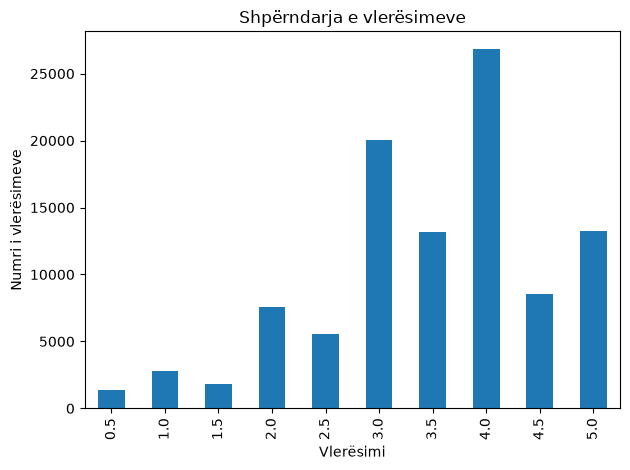

In [1]:
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

MOVIELENS_URL = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"

def read_movielens():
    for parent in (Path.cwd(), Path.cwd().parent):
        folder = parent / "data/ml-latest-small"
        if (folder / "movies.csv").is_file() and (folder / "ratings.csv").is_file():
            return pd.read_csv(folder / "movies.csv"), pd.read_csv(folder / "ratings.csv")
    with urlopen(MOVIELENS_URL, timeout=60) as response:
        with ZipFile(BytesIO(response.read())) as archive:
            return tuple(pd.read_csv(archive.open(f"ml-latest-small/{table}.csv"))
                         for table in ("movies", "ratings"))

raw_movies, raw_ratings = read_movielens()
display(pd.DataFrame({
    "Tabela": ["movies", "ratings"],
    "Rreshta": [len(raw_movies), len(raw_ratings)],
    "Vlera boshe": [raw_movies.isna().sum().sum(), raw_ratings.isna().sum().sum()],
    "Rreshta identikë": [raw_movies.duplicated().sum(), raw_ratings.duplicated().sum()],
}))
raw_ratings["rating"].value_counts().sort_index().plot.bar(
    xlabel="Vlerësimi", ylabel="Numri i vlerësimeve", title="Shpërndarja e vlerësimeve"
)
plt.tight_layout()
plt.show()

## 3. Përgatitja
Përjashtojmë filmat pa zhanër dhe vlerësimet për filma jashtë katalogut të pastruar. Për secilin çift përdorues–film ruajmë vlerësimin më të vonshëm. Titujt e njëjtë me ID të ndryshme ruhen.

In [2]:
def clean_data(movies, ratings):
    movies = movies.dropna(subset=["movieId", "title", "genres"])
    movies = movies.loc[movies["genres"].ne("(no genres listed)")].drop_duplicates("movieId")
    ratings = ratings.dropna(subset=["userId", "movieId", "rating", "timestamp"])
    ratings = ratings.loc[ratings["rating"].between(0.5, 5.0) & ratings["movieId"].isin(movies["movieId"])]
    ratings = ratings.sort_values(["timestamp", "movieId"]).drop_duplicates(["userId", "movieId"], keep="last")
    return movies.reset_index(drop=True), ratings.reset_index(drop=True)

movies, ratings = clean_data(raw_movies, raw_ratings)
print(f"{len(movies)} filma, {len(ratings)} vlerësime, {ratings['userId'].nunique()} përdorues")

9708 filma, 100789 vlerësime, 610 përdorues


## 4. Modelimi
Klasa nga `recommender.py` riprodhohet këtu për ekzekutim të pavarur.
Ajo kodon zhanret me TF-IDF. Kosinusi llogarit produktin skalar të dy vektorëve
të normalizuar. Kur dy kandidatë marrin pikë të njëjta, numri i vlerësimeve i rendit.

In [3]:
class ContentModel:
    """Finds movies with similar genres."""

    def __init__(self, movies, ratings):
        self.movies = movies.reset_index(drop=True)

        # Turn each movie's genres into a list of numbers (a "vector").
        # "Adventure|Animation|Children" -> one number per genre.
        # TF-IDF gives rare genres (e.g. "Film-Noir") more weight than
        # common ones (e.g. "Drama"), because rare genres say more about a movie.
        vectorizer = TfidfVectorizer(token_pattern=r"[^|]+")  # split on "|"
        self.vectors = vectorizer.fit_transform(self.movies["genres"])

        # How many ratings each movie has. Used to break ties:
        # many movies have exactly the same genres, so we show the well-known ones first.
        self.popularity = self.movies["movieId"].map(ratings["movieId"].value_counts()).fillna(0)

    def similar_movies(self, title, n=10):
        """Return the n movies whose genres are most similar to `title`."""
        row = self.movies.index[self.movies["title"] == title][0]

        # Cosine similarity = how much two vectors point in the same direction.
        # 1.0 = exactly the same genres, 0.0 = no genre in common.
        scores = cosine_similarity(self.vectors[row], self.vectors)[0]

        result = self.movies.assign(similarity=scores, popularity=self.popularity)
        result = result.drop(row)  # don't recommend the movie itself
        result = result.sort_values(["similarity", "popularity"], ascending=False)
        return result[["title", "genres", "similarity"]].head(n)

## 5. Vlerësimi
Për secilin përdorues me të paktën dy filma të vlerësuar ≥4, fshehim vlerësimin
e fundit të tillë dhe përdorim të parafunditin si film hyrës. Kandidatët përjashtojnë
filmat me vlerësime të tjera të atij përdoruesi. Popullaritetin e llogarisim pasi i
heqim të gjitha vlerësimet e fshehura. Ky është test offline me ndarje për përdorues.
Metadata dhe historiku global mund të përmbajnë informacion nga e ardhmja në raport
me një përdorues. Për simulim në kohë reale duhet një datë globale prerjeje.

In [4]:
def evaluate_ranking(movies, ratings, k=10):
    liked = ratings.loc[ratings["rating"].ge(4)]
    eligible = liked.groupby("userId").filter(lambda group: len(group) >= 2)
    targets = eligible.groupby("userId").tail(1)
    train = ratings.drop(index=targets.index)
    seeds = eligible.drop(index=targets.index).groupby("userId").tail(1).set_index("userId")["movieId"]

    model = ContentModel(movies, train)
    row_by_id = pd.Series(model.movies.index, index=model.movies["movieId"])
    seen = train.groupby("userId")["movieId"].agg(set)
    popularity = model.popularity
    hits = {"TF-IDF + kosinus": 0, "Popullaritet": 0}

    for user, target in targets[["userId", "movieId"]].itertuples(index=False, name=None):
        candidates = model.movies.loc[~model.movies["movieId"].isin(seen[user]), ["movieId"]].copy()
        similarity = cosine_similarity(model.vectors[row_by_id[seeds[user]]], model.vectors)[0]
        candidates["similarity"] = similarity[candidates.index]
        candidates["popularity"] = popularity.loc[candidates.index]
        cosine_top = candidates.sort_values(
            ["similarity", "popularity", "movieId"], ascending=[False, False, True]
        ).head(k)
        popular_top = candidates.sort_values(["popularity", "movieId"], ascending=[False, True]).head(k)
        hits["TF-IDF + kosinus"] += int(target in set(cosine_top["movieId"]))
        hits["Popullaritet"] += int(target in set(popular_top["movieId"]))

    return pd.DataFrame([
        {"Metoda": method, "Raste": len(targets), "Goditje": count, f"HitRate@{k}": count / len(targets)}
        for method, count in hits.items()
    ])

metrics = evaluate_ranking(movies, ratings)
display(metrics.round(4))

,Metoda,Raste,Goditje,HitRate@10
0,TF-IDF + kosinus,608,12,0.0197
1,Popullaritet,608,32,0.0526


## 6. Vënia në përdorim dhe etika
Ndrysho titullin ose `n` për të provuar një kërkesë të re. Filmave të rinj me
zhanre mund t’u llogaritet ngjashmëria edhe pa historik vlerësimesh.
Filtrat sipas zhanrit mund të ngushtojnë larminë. Popullariteti favorizon titujt
me ekspozim të lartë. Për përdorim real do të matnim edhe mbulimin e katalogut dhe
do të kufizonim ruajtjen e historikut të përdoruesit.

In [5]:
content = ContentModel(movies, ratings)

def rekomando_filma(title, n=10):
    if not isinstance(title, str) or not title.strip():
        raise ValueError("Shkruaj titullin e filmit.")
    if not isinstance(n, int) or not 1 <= n <= len(movies) - 1:
        raise ValueError("n duhet të jetë numër i plotë brenda madhësisë së katalogut.")
    title = title.strip()
    if title not in set(movies["title"]):
        raise ValueError(f"Titulli nuk u gjet: {title}")
    return content.similar_movies(title, n=n)

display(rekomando_filma("Toy Story (1995)", n=5).round(3))

,title,genres,similarity
3568,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,1.0
2355,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,1.0
1706,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,1.0
3000,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
6486,Shrek the Third (2007),Adventure|Animation|Children|Comedy|Fantasy,1.0
